# Early Prediction of Student Academic Risk (Prerequisite Course -> Subsequent Course)

Analysis code for the manuscript *Predicting Student Academic Risk in a Subsequent Mathematics Course from Prerequisite and In-Course Assessment Records*.

**Data.** The study used anonymised course-evaluation records for Batches 22-25. The data contain no student names or registration numbers and are **not included** in this repository. The notebook expects anonymised exports in `data/` (see `COHORT_CONFIG` in Phase 1b); students are referenced only by an anonymised `student_code`.


In [7]:
import glob
import re
import datetime as dt
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    accuracy_score, f1_score, recall_score, precision_score, make_scorer
)
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
plt.rcParams["figure.figsize"] = (7, 4)

# Folder holding the anonymised course-evaluation exports (not included in this repository).
DATA_DIR = "data"

# Anonymised student code column (assigned by the data provider). No names or registration numbers are used.
ID_COL = "student_code"
# Rows of the exported tables that belong to students carry a code matching this pattern.
ID_PATTERN = r"^[A-Za-z0-9\-]+$"


## Phase 1a — Parsing the Raw Evaluation Reports

In [40]:
def _flatten_level(df, level):
    return [str(x) for x in df.columns.get_level_values(level)]


def parse_evaluation_report(path):
    raw = pd.read_html(path)[0]

    lvl0 = _flatten_level(raw, 0)

    item_labels = _flatten_level(raw, 1)
    item_labels[0], item_labels[1], item_labels[2] = "Sr", "RegDt", ID_COL
    item_labels[3] = "_unused"

    data = raw.copy()
    data.columns = item_labels
    data[ID_COL] = data[ID_COL].astype(str).str.strip()
    data = data[data[ID_COL].str.match(ID_PATTERN)].reset_index(drop=True)

    for col in data.columns:
        if col in (ID_COL, "_unused", "Sr", "RegDt", "Grade"):
            continue
        data[col] = pd.to_numeric(data[col], errors="coerce")

    def cols_matching(pattern):
        return [c for c in data.columns if re.match(pattern, str(c))]

    as_item_cols = cols_matching(r"^As:\d+$")
    qz_item_cols = cols_matching(r"^Qz:\d+$")

    out = pd.DataFrame()
    out[ID_COL] = data[ID_COL]

    out["assign_total_score"] = data[as_item_cols].sum(axis=1, min_count=1) if as_item_cols else pd.NA
    out["assign_num_taken"] = data[as_item_cols].notna().sum(axis=1) if as_item_cols else 0
    out["assign_avg_score"] = data[as_item_cols].mean(axis=1) if as_item_cols else pd.NA
    out["assign_group_pct"] = data["As"] if "As" in data.columns else pd.NA

    out["quiz_total_score"] = data[qz_item_cols].sum(axis=1, min_count=1) if qz_item_cols else pd.NA
    out["quiz_num_taken"] = data[qz_item_cols].notna().sum(axis=1) if qz_item_cols else 0
    out["quiz_avg_score"] = data[qz_item_cols].mean(axis=1) if qz_item_cols else pd.NA
    out["quiz_group_pct"] = data["Qz"] if "Qz" in data.columns else pd.NA

    out["sessional1_pct"] = data["S-I"] if "S-I" in data.columns else pd.NA
    out["sessional2_pct"] = data["S-II"] if "S-II" in data.columns else pd.NA
    out["project_pct"] = data["Proj"] if "Proj" in data.columns else pd.NA
    out["final_pct"] = data["Final"] if "Final" in data.columns else pd.NA
    out["g_tot"] = data["G.Tot"] if "G.Tot" in data.columns else pd.NA
    out["grade"] = data["Grade"].astype(str).str.strip() if "Grade" in data.columns else pd.NA

    return out


def _parse_date(s):
    s = str(s).strip()
    for fmt in ("%d-%b-%Y", "%d-%B-%Y"):
        try:
            return dt.datetime.strptime(s, fmt)
        except ValueError:
            continue
    return None


def parse_early_semester_features(path):
    raw = pd.read_html(path)[0]
    lvl1 = [str(x) for x in raw.columns.get_level_values(1)]
    lvl2 = [str(x) for x in raw.columns.get_level_values(2)]
    last = [str(x) for x in raw.columns.get_level_values(raw.columns.nlevels - 1)]

    si_dates = [_parse_date(d) for lab, d in zip(lvl1, lvl2) if lab.startswith("S-I:")]
    si_dates = [d for d in si_dates if d is not None]
    cutoff = max(si_dates) if si_dates else None

    data = raw.copy()
    labels = list(lvl1)
    labels[0], labels[1], labels[2], labels[3] = "Sr", "RegDt", ID_COL, "_unused"
    data.columns = labels
    data[ID_COL] = data[ID_COL].astype(str).str.strip()
    data = data[data[ID_COL].str.match(ID_PATTERN)].reset_index(drop=True)

    early_item_cols, early_item_max = [], {}
    for lab, date_str, max_str in zip(lvl1, lvl2, last):
        if re.match(r"^(As|Qz):\d+$", lab) and cutoff is not None:
            d = _parse_date(date_str)
            if d is not None and d <= cutoff:
                early_item_cols.append(lab)
                try:
                    early_item_max[lab] = float(max_str)
                except ValueError:
                    early_item_max[lab] = None

    for c in early_item_cols:
        data[c] = pd.to_numeric(data[c], errors="coerce")

    if early_item_cols:
        earned = data[early_item_cols].sum(axis=1, min_count=1)
        possible = sum(v for v in early_item_max.values() if v)
        early_pct = (earned / possible * 100) if possible else pd.NA
        n_early_items = data[early_item_cols].notna().sum(axis=1)
    else:
        early_pct, n_early_items = pd.NA, 0

    return pd.DataFrame({
        ID_COL: data[ID_COL],
        "C2_early_pct": early_pct,
        "C2_early_items_taken": n_early_items,
    })


## Phase 1b — Merging Cohorts

In [9]:
def load_cohort(course1_glob, course2_glob, cohort_label, target_course):
    c1_files = sorted(glob.glob(course1_glob))
    c2_files = sorted(glob.glob(course2_glob))
    if not c1_files or not c2_files:
        raise FileNotFoundError(
            f"No files matched for cohort {cohort_label}: "
            f"{len(c1_files)} Course-1 files, {len(c2_files)} Course-2 files"
        )

    c1 = pd.concat([parse_evaluation_report(f) for f in c1_files], ignore_index=True)
    c2 = pd.concat([parse_evaluation_report(f) for f in c2_files], ignore_index=True)
    early = pd.concat([parse_early_semester_features(f) for f in c2_files], ignore_index=True)

    c1 = c1.add_prefix("C1_").rename(columns={f"C1_{ID_COL}": ID_COL})
    c2 = c2.add_prefix("C2_").rename(columns={f"C2_{ID_COL}": ID_COL})

    merged = c1.merge(c2, on=ID_COL, how="inner", suffixes=("", "_c2"))
    merged = merged.merge(early, on=ID_COL, how="left")
    merged["cohort"] = cohort_label
    merged["target_course"] = target_course
    return merged.drop_duplicates(subset=ID_COL).reset_index(drop=True)


# Expected (anonymised) file layout in DATA_DIR:
#   batch<B>_prerequisite_*.xls   (first-semester calculus evaluation reports)
#   batch<B>_subsequent_*.xls     (second-semester course evaluation reports)
COHORT_CONFIG = [
    {"cohort": 22, "course1_glob": f"{DATA_DIR}/batch22_prerequisite_*.xls",
     "course2_glob": f"{DATA_DIR}/batch22_subsequent_*.xls",
     "target_course": "Differential Equations"},
    {"cohort": 23, "course1_glob": f"{DATA_DIR}/batch23_prerequisite_*.xls",
     "course2_glob": f"{DATA_DIR}/batch23_subsequent_*.xls",
     "target_course": "Multivariable Calculus"},
    {"cohort": 24, "course1_glob": f"{DATA_DIR}/batch24_prerequisite_*.xls",
     "course2_glob": f"{DATA_DIR}/batch24_subsequent_*.xls",
     "target_course": "Multivariable Calculus"},
    {"cohort": 25, "course1_glob": f"{DATA_DIR}/batch25_prerequisite_*.xls",
     "course2_glob": f"{DATA_DIR}/batch25_subsequent_*.xls",
     "target_course": "Multivariable Calculus"},
]

TRAIN_COHORTS = [22, 23, 24]
VAL_COHORT = 25

parts = [load_cohort(c["course1_glob"], c["course2_glob"], c["cohort"], c["target_course"])
          for c in COHORT_CONFIG]
df = pd.concat(parts, ignore_index=True)

print(df.groupby(["cohort", "target_course"]).size().rename("matched students"))
print(f"\nTotal students across all batches: {len(df)}")
df.drop(columns=ID_COL).head()   # student codes are never displayed


cohort  target_course         
22      Differential Equations    146
23      Multivariable Calculus    154
24      Multivariable Calculus    119
25      Multivariable Calculus    160
Name: matched students, dtype: int64

Total students across all batches: 579


,C1_assign_total_score,C1_assign_num_taken,C1_assign_avg_score,C1_assign_group_pct,C1_quiz_total_score,C1_quiz_num_taken,C1_quiz_avg_score,C1_quiz_group_pct,C1_sessional1_pct,C1_sessional2_pct,C1_project_pct,C1_final_pct,C1_g_tot,C1_grade,C2_assign_total_score,C2_assign_num_taken,C2_assign_avg_score,C2_assign_group_pct,C2_quiz_total_score,C2_quiz_num_taken,C2_quiz_avg_score,C2_quiz_group_pct,C2_sessional1_pct,C2_sessional2_pct,C2_project_pct,C2_final_pct,C2_g_tot,C2_grade,C2_early_pct,C2_early_items_taken,cohort,target_course
0,581.0,4,145.250000,4.82,80.0,8,10.000000,6.76,6.50,4.75,6.90,28.66,58.41,B-,155.0,3,51.666667,1.41,101.5,13,7.807692,6.51,9.15,7.10,6.72,30.18,61.09,B,68.461538,4,22,Differential Equations
1,534.0,4,133.500000,4.36,54.0,10,5.400000,4.46,6.00,3.00,6.34,12.00,36.18,D,438.0,4,109.500000,3.32,44.5,11,4.045455,4.07,2.54,1.50,6.81,9.81,28.08,F,12.307692,3,22,Differential Equations
2,506.0,4,126.500000,4.26,63.0,10,6.300000,4.51,2.25,3.50,7.00,15.33,36.86,D,590.0,4,147.500000,4.66,48.5,10,4.850000,4.05,4.05,1.80,6.62,5.55,26.76,F,30.000000,4,22,Differential Equations
3,337.0,3,112.333333,2.54,60.5,9,6.722222,5.12,5.62,4.37,6.53,17.33,41.54,D+,20.0,1,20.000000,0.19,37.5,13,2.884615,3.10,3.45,4.09,7.00,10.18,28.03,F,11.538462,4,22,Differential Equations
4,556.0,4,139.000000,4.58,79.0,10,7.900000,5.80,7.62,4.25,7.00,26.66,55.94,C+,580.0,4,145.000000,4.57,66.0,12,5.500000,5.08,6.15,7.00,6.72,26.66,56.20,B-,30.000000,3,22,Differential Equations


## Phase 1c — Target Distribution

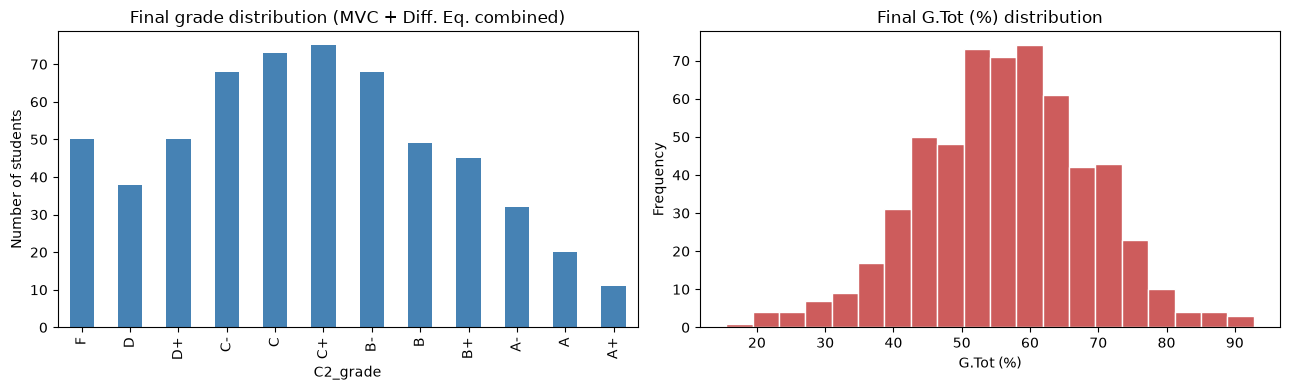

count    579.000000
mean      56.458618
std       12.427132
min       15.510000
25%       48.135000
50%       57.040000
75%       64.945000
max       92.760000
Name: C2_g_tot, dtype: float64

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))

grade_order = ["F", "D", "D+", "C-", "C", "C+", "B-", "B", "B+", "A-", "A", "A+"]
df["C2_grade"].value_counts().reindex(grade_order).plot(kind="bar", ax=ax[0], color="steelblue")
ax[0].set_title("Final grade distribution (MVC + Diff. Eq. combined)")
ax[0].set_ylabel("Number of students")

df["C2_g_tot"].plot(kind="hist", bins=20, ax=ax[1], color="indianred", edgecolor="white")
ax[1].set_title("Final G.Tot (%) distribution")
ax[1].set_xlabel("G.Tot (%)")

plt.tight_layout()
plt.show()
df["C2_g_tot"].describe()


## Phase 1d — Risk Categories

In [11]:
def label_risk(grade):
    at_risk = {"F", "D", "D+"}
    high = {"B", "B+", "A-", "A", "A+"}
    if grade in at_risk:
        return "At-Risk"
    elif grade in high:
        return "High Achiever"
    return "Stable"

df["risk_category"] = df["C2_grade"].apply(label_risk)
df["risk_category"].value_counts()


risk_category
Stable           284
High Achiever    157
At-Risk          138
Name: count, dtype: int64

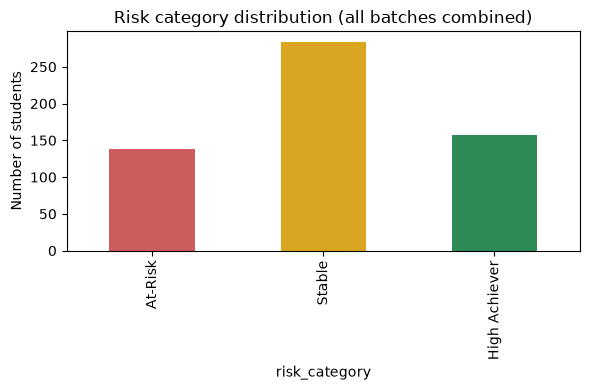

In [12]:
fig, ax = plt.subplots(figsize=(6, 4))
df["risk_category"].value_counts().loc[["At-Risk", "Stable", "High Achiever"]].plot(
    kind="bar", color=["indianred", "goldenrod", "seagreen"], ax=ax
)
ax.set_title("Risk category distribution (all batches combined)")
ax.set_ylabel("Number of students")
plt.tight_layout()
plt.show()


## Phase 2 — The Three Prediction Scenarios

In [13]:
S1_FEATURES = [
    "C1_assign_group_pct", "C1_quiz_group_pct",
    "C1_sessional1_pct", "C1_sessional2_pct",
    "C1_project_pct", "C1_final_pct", "C1_g_tot",
]

S2_FEATURES = S1_FEATURES + ["C2_early_pct"]

S3_FEATURES = S2_FEATURES + [
    "C2_assign_group_pct", "C2_quiz_group_pct",
    "C2_sessional1_pct", "C2_sessional2_pct", "C2_project_pct",
]

SCENARIOS = {"Scenario 1 (Pre-Semester)": S1_FEATURES,
             "Scenario 2 (Early-Semester)": S2_FEATURES,
             "Scenario 3 (Mid-Semester)": S3_FEATURES}

for name, feats in SCENARIOS.items():
    n_rows = df[feats + ["risk_category"]].dropna().shape[0]
    print(f"{name}: {len(feats)} features, {n_rows}/{len(df)} students with complete data")


Scenario 1 (Pre-Semester): 7 features, 578/579 students with complete data
Scenario 2 (Early-Semester): 8 features, 578/579 students with complete data
Scenario 3 (Mid-Semester): 13 features, 573/579 students with complete data


## Phase 3 & 4 — Training and Validation

In [14]:
def get_models():
    return {
        "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
        "Random Forest": RandomForestClassifier(n_estimators=300, max_depth=5,
                                                  class_weight="balanced", random_state=42),
        "Gradient Boosting": GradientBoostingClassifier(n_estimators=200, max_depth=3,
                                                          random_state=42),
    }


def run_scenario(feats, scenario_name):
    sub = df[feats + ["risk_category", "cohort", ID_COL]].dropna()
    train = sub[sub["cohort"].isin(TRAIN_COHORTS)]
    val = sub[sub["cohort"] == VAL_COHORT]

    Xtr, ytr = train[feats], train["risk_category"]
    Xval, yval = val[feats], val["risk_category"]

    scaler = StandardScaler().fit(Xtr)
    Xtr_s, Xval_s = scaler.transform(Xtr), scaler.transform(Xval)

    results = []
    fitted = {}
    for model_name, model in get_models().items():
        model.fit(Xtr_s, ytr)
        pred = model.predict(Xval_s)
        results.append({
            "Scenario": scenario_name,
            "Model": model_name,
            "Accuracy": accuracy_score(yval, pred),
            "F1 (macro)": f1_score(yval, pred, average="macro"),
            "At-Risk Recall": recall_score(yval, pred, labels=["At-Risk"], average="macro"),
            "At-Risk Precision": precision_score(yval, pred, labels=["At-Risk"], average="macro", zero_division=0),
            "n_train": len(train), "n_val": len(val),
        })
        fitted[model_name] = (model, scaler, Xval, yval, pred)
    return pd.DataFrame(results), fitted


all_results, all_fitted = [], {}
for scenario_name, feats in SCENARIOS.items():
    res, fitted = run_scenario(feats, scenario_name)
    all_results.append(res)
    all_fitted[scenario_name] = fitted

results_df = pd.concat(all_results, ignore_index=True)
results_df.round(3)


,Scenario,Model,Accuracy,F1 (macro),At-Risk Recall,At-Risk Precision,n_train,n_val
0,Scenario 1 (Pre-Semester),Logistic Regression,0.306,0.224,0.116,1.000,418,160
1,Scenario 1 (Pre-Semester),Random Forest,0.612,0.620,0.651,0.571,418,160
2,Scenario 1 (Pre-Semester),Gradient Boosting,0.556,0.491,0.140,0.545,418,160
3,Scenario 2 (Early-Semester),Logistic Regression,0.300,0.214,0.116,1.000,418,160
4,Scenario 2 (Early-Semester),Random Forest,0.556,0.563,0.488,0.750,418,160
5,Scenario 2 (Early-Semester),Gradient Boosting,0.581,0.514,0.186,0.615,418,160
6,Scenario 3 (Mid-Semester),Logistic Regression,0.405,0.388,0.488,1.000,415,158
7,Scenario 3 (Mid-Semester),Random Forest,0.570,0.566,0.366,1.000,415,158
8,Scenario 3 (Mid-Semester),Gradient Boosting,0.513,0.487,0.244,1.000,415,158


## Phase 4a — At-Risk Recall Across Scenarios

Scenario,Scenario 1 (Pre-Semester),Scenario 2 (Early-Semester),Scenario 3 (Mid-Semester)
Model,,,
Gradient Boosting,0.140,0.186,0.244
Logistic Regression,0.116,0.116,0.488
Random Forest,0.651,0.488,0.366


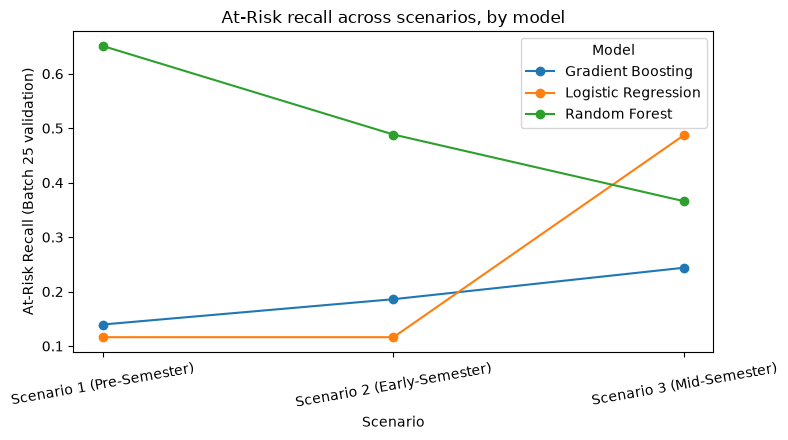

In [15]:
pivot = results_df.pivot_table(index="Model", columns="Scenario",
                                 values="At-Risk Recall")[list(SCENARIOS.keys())]
display(pivot.round(3))

fig, ax = plt.subplots(figsize=(8, 4.5))
pivot.T.plot(marker="o", ax=ax)
ax.set_ylabel("At-Risk Recall (Batch 25 validation)")
ax.set_title("At-Risk recall across scenarios, by model")
ax.set_xticks(range(len(SCENARIOS)))
ax.set_xticklabels(list(SCENARIOS.keys()), rotation=10)
ax.legend(title="Model")
plt.tight_layout()
plt.show()


## Phase 4b — Confusion Matrices (Best Model per Scenario)

,Scenario,Model,Accuracy,F1 (macro),At-Risk Recall
1,Scenario 1 (Pre-Semester),Random Forest,0.612,0.620,0.651
4,Scenario 2 (Early-Semester),Random Forest,0.556,0.563,0.488
6,Scenario 3 (Mid-Semester),Logistic Regression,0.405,0.388,0.488


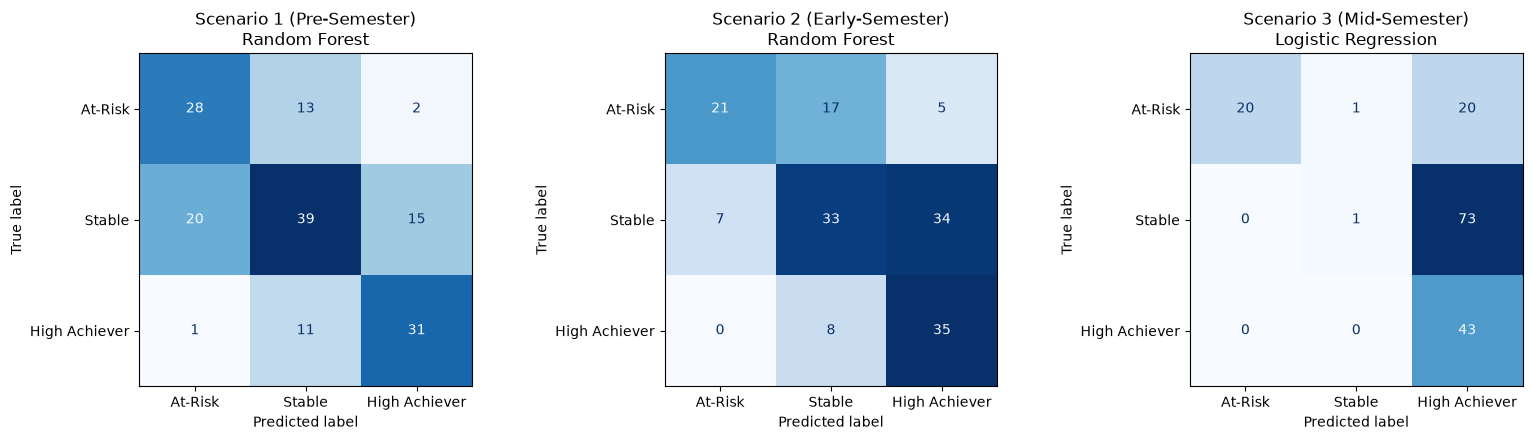

In [16]:
best_per_scenario = results_df.loc[results_df.groupby("Scenario")["At-Risk Recall"].idxmax()]
display(best_per_scenario[["Scenario", "Model", "Accuracy", "F1 (macro)", "At-Risk Recall"]].round(3))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
labels_order = ["At-Risk", "Stable", "High Achiever"]
for ax, (_, row) in zip(axes, best_per_scenario.iterrows()):
    model, scaler, Xval, yval, pred = all_fitted[row["Scenario"]][row["Model"]]
    cm = confusion_matrix(yval, pred, labels=labels_order)
    ConfusionMatrixDisplay(cm, display_labels=labels_order).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"{row['Scenario']}\n{row['Model']}")
plt.tight_layout()
plt.show()


## Phase 5 — Feature Importance

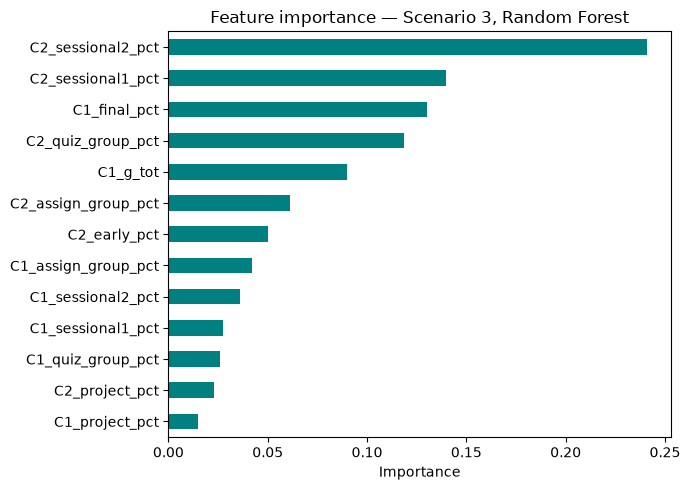

In [17]:
rf_model, scaler, Xval, yval, pred = all_fitted["Scenario 3 (Mid-Semester)"]["Random Forest"]
importances = pd.Series(rf_model.feature_importances_, index=S3_FEATURES).sort_values()

fig, ax = plt.subplots(figsize=(7, 5))
importances.plot(kind="barh", ax=ax, color="teal")
ax.set_title("Feature importance — Scenario 3, Random Forest")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.show()


## Phase 6 — Leakage-Free Threshold & Hyperparameter Selection

In [18]:
sub = df[S3_FEATURES + ["risk_category", "cohort"]].dropna()
train_full = sub[sub["cohort"].isin(TRAIN_COHORTS)]
batch25 = sub[sub["cohort"] == VAL_COHORT]   # stays completely untouched until the final cell

dev_train = train_full[train_full["cohort"] != 24]
dev_val = train_full[train_full["cohort"] == 24]
scaler_dev = StandardScaler().fit(dev_train[S3_FEATURES])

def at_risk_recall(y_true, y_pred):
    return recall_score(y_true, y_pred, labels=["At-Risk"], average="macro")
at_risk_scorer = make_scorer(at_risk_recall)

# Hyperparameters selected using ONLY dev_train (5-fold CV inside dev_train)
param_grid = {
    "C": [0.001, 0.01, 0.1, 1, 10, 100],
    "class_weight": ["balanced", {"At-Risk": 2, "Stable": 1, "High Achiever": 1},
                      {"At-Risk": 3, "Stable": 1, "High Achiever": 1}],
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid_search = GridSearchCV(LogisticRegression(max_iter=2000), param_grid, scoring=at_risk_scorer, cv=cv, n_jobs=-1)
grid_search.fit(scaler_dev.transform(dev_train[S3_FEATURES]), dev_train["risk_category"])
print("Best hyperparams (selected using dev_train only):", grid_search.best_params_)

# Threshold selected using dev_val -- Batch 24, held out from training,
# but still never touching Batch 25.
def predict_with_threshold(proba, classes, at_risk_idx, threshold):
    preds = []
    for row in proba:
        if row[at_risk_idx] >= threshold:
            preds.append("At-Risk")
        else:
            other_idx = [i for i in range(len(classes)) if i != at_risk_idx]
            preds.append(classes[max(other_idx, key=lambda i: row[i])])
    return np.array(preds)

dev_model = grid_search.best_estimator_
classes = list(dev_model.classes_)
at_risk_idx = classes.index("At-Risk")
proba_dev_val = dev_model.predict_proba(scaler_dev.transform(dev_val[S3_FEATURES]))

best_threshold, best_recall = 0.5, -1
threshold_log = []
for th in np.arange(0.15, 0.55, 0.025):
    preds = predict_with_threshold(proba_dev_val, classes, at_risk_idx, th)
    rec = recall_score(dev_val["risk_category"], preds, labels=["At-Risk"], average="macro")
    prec = precision_score(dev_val["risk_category"], preds, labels=["At-Risk"], average="macro", zero_division=0)
    threshold_log.append({"Threshold": th, "Recall (dev_val)": rec, "Precision (dev_val)": prec})
    if prec >= 0.5 and rec > best_recall:
        best_recall, best_threshold = rec, th

pd.DataFrame(threshold_log).round(3)

Best hyperparams (selected using dev_train only): {'C': 0.001, 'class_weight': {'At-Risk': 3, 'Stable': 1, 'High Achiever': 1}}


,Threshold,Recall (dev_val),Precision (dev_val)
0,0.150,1.000,0.154
1,0.175,1.000,0.157
2,0.200,1.000,0.159
3,0.225,1.000,0.165
4,0.250,1.000,0.173
5,0.275,1.000,0.182
6,0.300,1.000,0.200
7,0.325,1.000,0.228
8,0.350,1.000,0.247
9,0.375,1.000,0.261


## Phase 6a — Final Single Evaluation on Batch 25

In [19]:
print(f"Selected threshold: {best_threshold:.3f} (recall={best_recall:.3f} on dev_val, Batch 24)")

# Refit on ALL of train_full (batches 22-24) with the chosen, fixed hyperparams
scaler_final = StandardScaler().fit(train_full[S3_FEATURES])
final_model = LogisticRegression(max_iter=2000, **grid_search.best_params_)
final_model.fit(scaler_final.transform(train_full[S3_FEATURES]), train_full["risk_category"])

# ONE single evaluation on Batch 25 -- untouched until this exact line
classes_final = list(final_model.classes_)
at_risk_idx_final = classes_final.index("At-Risk")
proba_batch25 = final_model.predict_proba(scaler_final.transform(batch25[S3_FEATURES]))
final_preds = predict_with_threshold(proba_batch25, classes_final, at_risk_idx_final, best_threshold)

point_recall = recall_score(batch25["risk_category"], final_preds, labels=["At-Risk"], average="macro")
point_precision = precision_score(batch25["risk_category"], final_preds, labels=["At-Risk"], average="macro", zero_division=0)
point_accuracy = accuracy_score(batch25["risk_category"], final_preds)
point_f1 = f1_score(batch25["risk_category"], final_preds, average="macro")

print("=== FINAL, single evaluation on Batch 25 ===")
print(f"Accuracy: {point_accuracy:.3f}  F1: {point_f1:.3f}  At-Risk Recall: {point_recall:.3f}  At-Risk Precision: {point_precision:.3f}")

Selected threshold: 0.475 (recall=0.778 on dev_val, Batch 24)
=== FINAL, single evaluation on Batch 25 ===
Accuracy: 0.684  F1: 0.635  At-Risk Recall: 0.293  At-Risk Precision: 0.923


## Phase 6b — Bootstrap Confidence Intervals

In [20]:
rng = np.random.default_rng(42)
y_true = batch25["risk_category"].values
y_pred = final_preds
n = len(y_true)
n_boot = 3000

boot_recalls, boot_precisions = [], []
for _ in range(n_boot):
    idx = rng.integers(0, n, n)
    yt, yp = y_true[idx], y_pred[idx]
    if (yt == "At-Risk").sum() == 0:
        continue
    boot_recalls.append(recall_score(yt, yp, labels=["At-Risk"], average="macro"))
    boot_precisions.append(precision_score(yt, yp, labels=["At-Risk"], average="macro", zero_division=0))

rec_lo, rec_hi = np.percentile(boot_recalls, [2.5, 97.5])
prec_lo, prec_hi = np.percentile(boot_precisions, [2.5, 97.5])

print(f"At-Risk Recall:    {point_recall:.3f}   95% CI [{rec_lo:.3f}, {rec_hi:.3f}]")
print(f"At-Risk Precision: {point_precision:.3f}   95% CI [{prec_lo:.3f}, {prec_hi:.3f}]")

At-Risk Recall:    0.293   95% CI [0.160, 0.441]
At-Risk Precision: 0.923   95% CI [0.750, 1.000]


## Summary

In [21]:
print("Baseline Scenario 3 (Logistic Regression, threshold 0.5, class_weight='balanced'):")
print(f"  Accuracy: {results_df[(results_df.Scenario=='Scenario 3 (Mid-Semester)') & (results_df.Model=='Logistic Regression')]['Accuracy'].values[0]:.3f}")
print(f"  At-Risk Recall: 0.488")

print("\nAfter leakage-free threshold + hyperparameter selection (single evaluation on Batch 25):")
print(f"  Accuracy: {point_accuracy:.3f}")
print(f"  At-Risk Recall: {point_recall:.3f}  95% CI [{rec_lo:.3f}, {rec_hi:.3f}]")
print(f"  At-Risk Precision: {point_precision:.3f}  95% CI [{prec_lo:.3f}, {prec_hi:.3f}]")

Baseline Scenario 3 (Logistic Regression, threshold 0.5, class_weight='balanced'):
  Accuracy: 0.405
  At-Risk Recall: 0.488

After leakage-free threshold + hyperparameter selection (single evaluation on Batch 25):
  Accuracy: 0.684
  At-Risk Recall: 0.293  95% CI [0.160, 0.441]
  At-Risk Precision: 0.923  95% CI [0.750, 1.000]


## Phase 7 — Delta Features, SMOTE, and Stratified K-Fold Across All Training Batches

In [22]:
df["C2_sess_delta"] = df["C2_sessional2_pct"] - df["C2_sessional1_pct"]
df["C1_sess_delta"] = df["C1_sessional2_pct"] - df["C1_sessional1_pct"]
df["cross_course_delta"] = df["C2_sessional1_pct"] - df["C1_g_tot"]
df["cross_course_early_delta"] = df["C2_early_pct"] - df["C1_g_tot"]
df["quiz_trend"] = df["C2_quiz_group_pct"] - df["C1_quiz_group_pct"]
df["assign_trend"] = df["C2_assign_group_pct"] - df["C1_assign_group_pct"]

DELTA_FEATURES = ["C2_sess_delta", "C1_sess_delta", "cross_course_delta",
                   "cross_course_early_delta", "quiz_trend", "assign_trend"]
S3_FEATURES_V2 = S3_FEATURES + DELTA_FEATURES

sub2 = df[S3_FEATURES_V2 + ["risk_category", "cohort"]].dropna()
train_full2 = sub2[sub2["cohort"].isin(TRAIN_COHORTS)].reset_index(drop=True)
batch25_v2 = sub2[sub2["cohort"] == VAL_COHORT].reset_index(drop=True)

print(f"Train (batches 22-24): {len(train_full2)} students | Batch 25 (held out): {len(batch25_v2)} students")
train_full2["risk_category"].value_counts()

Train (batches 22-24): 415 students | Batch 25 (held out): 158 students


risk_category
Stable           209
High Achiever    114
At-Risk           92
Name: count, dtype: int64

In [23]:
from imblearn.over_sampling import SMOTE
import itertools

X_train_full2 = train_full2[S3_FEATURES_V2].values
y_train_full2 = train_full2["risk_category"].values

C_GRID = [0.001, 0.01, 0.1, 1, 10, 100]
CW_GRID = ["balanced", {"At-Risk": 2, "Stable": 1, "High Achiever": 1},
           {"At-Risk": 3, "Stable": 1, "High Achiever": 1}]
K_NEIGHBORS_GRID = [3, 5]
THRESHOLDS_V2 = np.arange(0.15, 0.60, 0.025)
PRECISION_FLOOR = 0.5

outer_cv2 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
folds2 = list(outer_cv2.split(X_train_full2, y_train_full2))

results_grid = []
for C, cw, k_nb in itertools.product(C_GRID, CW_GRID, K_NEIGHBORS_GRID):
    oof_proba = np.zeros((len(y_train_full2), 3))
    classes_ref = None
    for tr_idx, va_idx in folds2:
        Xtr, Xva = X_train_full2[tr_idx], X_train_full2[va_idx]
        ytr, yva = y_train_full2[tr_idx], y_train_full2[va_idx]

        scaler_f = StandardScaler().fit(Xtr)
        Xtr_s, Xva_s = scaler_f.transform(Xtr), scaler_f.transform(Xva)

        min_class_count = pd.Series(ytr).value_counts().min()
        k_eff = max(min(k_nb, min_class_count - 1), 1)
        sm = SMOTE(random_state=42, k_neighbors=k_eff)
        Xtr_res, ytr_res = sm.fit_resample(Xtr_s, ytr)

        clf = LogisticRegression(max_iter=2000, C=C, class_weight=cw)
        clf.fit(Xtr_res, ytr_res)
        classes_ref = list(clf.classes_)
        oof_proba[va_idx] = clf.predict_proba(Xva_s)

    at_risk_idx2 = classes_ref.index("At-Risk")
    for th in THRESHOLDS_V2:
        preds = predict_with_threshold(oof_proba, classes_ref, at_risk_idx2, th)
        rec = recall_score(y_train_full2, preds, labels=["At-Risk"], average="macro")
        prec = precision_score(y_train_full2, preds, labels=["At-Risk"], average="macro", zero_division=0)
        results_grid.append({"C": C, "class_weight": str(cw), "k_neighbors": k_nb,
                              "threshold": round(th, 3), "OOF Recall": rec, "OOF Precision": prec})

grid_df = pd.DataFrame(results_grid)
valid = grid_df[grid_df["OOF Precision"] >= PRECISION_FLOOR]
best_row = valid.loc[valid["OOF Recall"].idxmax()]
print("Selected configuration (OOF, across batches 22-24, precision floor 0.5):")
print(best_row)

Selected configuration (OOF, across batches 22-24, precision floor 0.5):
C                                                          0.001
class_weight     {'At-Risk': 2, 'Stable': 1, 'High Achiever': 1}
k_neighbors                                                    5
threshold                                                  0.475
OOF Recall                                              0.967391
OOF Precision                                                0.5
Name: 67, dtype: object


In [24]:
best_C2 = best_row["C"]
best_cw2 = eval(best_row["class_weight"]) if best_row["class_weight"] != "balanced" else "balanced"
best_k2 = int(best_row["k_neighbors"])
best_threshold2 = best_row["threshold"]

scaler_final2 = StandardScaler().fit(X_train_full2)
X_train_final2_s = scaler_final2.transform(X_train_full2)

min_class_count_full = pd.Series(y_train_full2).value_counts().min()
k_eff_final = min(best_k2, min_class_count_full - 1)
sm_final2 = SMOTE(random_state=42, k_neighbors=k_eff_final)
X_res2, y_res2 = sm_final2.fit_resample(X_train_final2_s, y_train_full2)

final_model2 = LogisticRegression(max_iter=2000, C=best_C2, class_weight=best_cw2)
final_model2.fit(X_res2, y_res2)

classes_final2 = list(final_model2.classes_)
at_risk_idx_final2 = classes_final2.index("At-Risk")
X_batch25_v2_s = scaler_final2.transform(batch25_v2[S3_FEATURES_V2].values)
proba_batch25_v2 = final_model2.predict_proba(X_batch25_v2_s)
final_preds2 = predict_with_threshold(proba_batch25_v2, classes_final2, at_risk_idx_final2, best_threshold2)

y_true_b25_v2 = batch25_v2["risk_category"].values
point_recall2 = recall_score(y_true_b25_v2, final_preds2, labels=["At-Risk"], average="macro")
point_precision2 = precision_score(y_true_b25_v2, final_preds2, labels=["At-Risk"], average="macro", zero_division=0)
point_accuracy2 = accuracy_score(y_true_b25_v2, final_preds2)
point_f1_2 = f1_score(y_true_b25_v2, final_preds2, average="macro")

print("=== FINAL, single evaluation on Batch 25 (delta features + SMOTE + Stratified K-Fold) ===")
print(f"Accuracy: {point_accuracy2:.3f}  F1: {point_f1_2:.3f}  At-Risk Recall: {point_recall2:.3f}  At-Risk Precision: {point_precision2:.3f}")

=== FINAL, single evaluation on Batch 25 (delta features + SMOTE + Stratified K-Fold) ===
Accuracy: 0.468  F1: 0.447  At-Risk Recall: 0.732  At-Risk Precision: 0.833


In [25]:
rng2 = np.random.default_rng(42)
n2 = len(y_true_b25_v2)
n_boot = 3000
boot_recalls2, boot_precisions2 = [], []
for _ in range(n_boot):
    idx = rng2.integers(0, n2, n2)
    yt, yp = y_true_b25_v2[idx], final_preds2[idx]
    if (yt == "At-Risk").sum() == 0:
        continue
    boot_recalls2.append(recall_score(yt, yp, labels=["At-Risk"], average="macro"))
    boot_precisions2.append(precision_score(yt, yp, labels=["At-Risk"], average="macro", zero_division=0))

rec_lo2, rec_hi2 = np.percentile(boot_recalls2, [2.5, 97.5])
prec_lo2, prec_hi2 = np.percentile(boot_precisions2, [2.5, 97.5])
print(f"At-Risk Recall:    {point_recall2:.3f}   95% CI [{rec_lo2:.3f}, {rec_hi2:.3f}]")
print(f"At-Risk Precision: {point_precision2:.3f}   95% CI [{prec_lo2:.3f}, {prec_hi2:.3f}]")

print()
print("=== COMPARISON: Phase 6 (single dev batch) vs Phase 7 (delta features + SMOTE + K-Fold) ===")
print(f"Phase 6  -> Recall: {point_recall:.3f}  95% CI [{rec_lo:.3f}, {rec_hi:.3f}]   Precision: {point_precision:.3f}  95% CI [{prec_lo:.3f}, {prec_hi:.3f}]")
print(f"Phase 7  -> Recall: {point_recall2:.3f}  95% CI [{rec_lo2:.3f}, {rec_hi2:.3f}]   Precision: {point_precision2:.3f}  95% CI [{prec_lo2:.3f}, {prec_hi2:.3f}]")

At-Risk Recall:    0.732   95% CI [0.590, 0.861]
At-Risk Precision: 0.833   95% CI [0.700, 0.947]

=== COMPARISON: Phase 6 (single dev batch) vs Phase 7 (delta features + SMOTE + K-Fold) ===
Phase 6  -> Recall: 0.293  95% CI [0.160, 0.441]   Precision: 0.923  95% CI [0.750, 1.000]
Phase 7  -> Recall: 0.732  95% CI [0.590, 0.861]   Precision: 0.833  95% CI [0.700, 0.947]


## Phase 8 — Per-Class Diagnostics on the Phase 7 Model

In [26]:
from sklearn.metrics import confusion_matrix, classification_report

labels_order = ["At-Risk", "Stable", "High Achiever"]
cm = confusion_matrix(y_true_b25_v2, final_preds2, labels=labels_order)
cm_df = pd.DataFrame(cm, index=[f"True {l}" for l in labels_order], columns=[f"Pred {l}" for l in labels_order])
print("Confusion matrix, Batch 25 (Phase 7 model):")
print(cm_df)
print()
print(classification_report(y_true_b25_v2, final_preds2, labels=labels_order, digits=3))

Confusion matrix, Batch 25 (Phase 7 model):
                    Pred At-Risk  Pred Stable  Pred High Achiever
True At-Risk                  30            4                   7
True Stable                    6            1                  67
True High Achiever             0            0                  43

               precision    recall  f1-score   support

      At-Risk      0.833     0.732     0.779        41
       Stable      0.200     0.014     0.025        74
High Achiever      0.368     1.000     0.537        43

     accuracy                          0.468       158
    macro avg      0.467     0.582     0.447       158
 weighted avg      0.410     0.468     0.360       158



**Finding:** the drop is not a normal recall/precision trade-off spread evenly across classes. At-Risk detection is solid (precision 0.833, recall 0.732) and zero High Achievers are ever misclassified as At-Risk, so the early-warning function itself is not compromised. The problem is specific: only 1 of 74 Stable students is correctly labeled, with 67 of them predicted as High Achiever instead. The 3-class model cannot reliably separate a borderline-passing student from a comfortably-succeeding one on the current feature set.

An attempted fix — restricting SMOTE to oversample only the At-Risk class (previously it also inflated High Achiever to match the majority count) and adding a Stable-recall floor to the hyperparameter search — held up during cross-validation but did not resolve the collapse on the actual Batch 25 evaluation, suggesting this is a real separability limit rather than a tunable artifact.

## Phase 9 — Binary Reframing: At-Risk vs. Not-At-Risk

In [27]:
df["binary_label"] = np.where(df["risk_category"] == "At-Risk", "At-Risk", "Not-At-Risk")

sub_bin = df[S3_FEATURES_V2 + ["binary_label", "cohort"]].dropna()
train_bin = sub_bin[sub_bin["cohort"].isin(TRAIN_COHORTS)].reset_index(drop=True)
batch25_bin = sub_bin[sub_bin["cohort"] == VAL_COHORT].reset_index(drop=True)

X_train_bin = train_bin[S3_FEATURES_V2].values
y_train_bin = train_bin["binary_label"].values
print("Training class counts:", pd.Series(y_train_bin).value_counts().to_dict())

Training class counts: {'Not-At-Risk': 323, 'At-Risk': 92}


In [28]:
C_GRID_B = [0.001, 0.01, 0.1, 1, 10, 100]
CW_GRID_B = ["balanced", {"At-Risk": 2, "Not-At-Risk": 1}, {"At-Risk": 3, "Not-At-Risk": 1}]
K_NEIGHBORS_GRID_B = [3, 5]
THRESHOLDS_B = np.arange(0.15, 0.60, 0.025)

outer_cv_b = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
folds_b = list(outer_cv_b.split(X_train_bin, y_train_bin))

def predict_binary(proba, classes, at_risk_idx, threshold):
    return np.array(["At-Risk" if row[at_risk_idx] >= threshold else "Not-At-Risk" for row in proba])

results_grid_b = []
for C, cw, k_nb in itertools.product(C_GRID_B, CW_GRID_B, K_NEIGHBORS_GRID_B):
    oof_proba = np.zeros((len(y_train_bin), 2))
    classes_ref = None
    for tr_idx, va_idx in folds_b:
        Xtr, Xva = X_train_bin[tr_idx], X_train_bin[va_idx]
        ytr, yva = y_train_bin[tr_idx], y_train_bin[va_idx]
        scaler_b = StandardScaler().fit(Xtr)
        Xtr_s, Xva_s = scaler_b.transform(Xtr), scaler_b.transform(Xva)
        counts = pd.Series(ytr).value_counts()
        k_eff = max(min(k_nb, counts.get("At-Risk", 1) - 1), 1)
        sm = SMOTE(random_state=42, k_neighbors=k_eff)
        Xtr_res, ytr_res = sm.fit_resample(Xtr_s, ytr)
        clf = LogisticRegression(max_iter=2000, C=C, class_weight=cw)
        clf.fit(Xtr_res, ytr_res)
        classes_ref = list(clf.classes_)
        oof_proba[va_idx] = clf.predict_proba(Xva_s)
    at_risk_idx_b = classes_ref.index("At-Risk")
    for th in THRESHOLDS_B:
        preds = predict_binary(oof_proba, classes_ref, at_risk_idx_b, th)
        rec = recall_score(y_train_bin, preds, pos_label="At-Risk")
        prec = precision_score(y_train_bin, preds, pos_label="At-Risk", zero_division=0)
        results_grid_b.append({"C": C, "class_weight": str(cw), "k_neighbors": k_nb,
                                "threshold": round(th, 3), "OOF Recall": rec, "OOF Precision": prec})

grid_df_b = pd.DataFrame(results_grid_b)
valid_b = grid_df_b[grid_df_b["OOF Precision"] >= 0.5]
best_row_b = valid_b.loc[valid_b["OOF Recall"].idxmax()]
print("Selected configuration (binary):")
print(best_row_b)

Selected configuration (binary):
C                                            0.01
class_weight     {'At-Risk': 2, 'Not-At-Risk': 1}
k_neighbors                                     3
threshold                                   0.525
OOF Recall                               0.967391
OOF Precision                                 0.5
Name: 159, dtype: object


In [29]:
best_C_b = best_row_b["C"]
best_cw_b = eval(best_row_b["class_weight"]) if best_row_b["class_weight"] != "balanced" else "balanced"
best_k_b = int(best_row_b["k_neighbors"])
best_threshold_b = best_row_b["threshold"]

scaler_final_b = StandardScaler().fit(X_train_bin)
X_train_final_b_s = scaler_final_b.transform(X_train_bin)
counts_full_b = pd.Series(y_train_bin).value_counts()
k_eff_final_b = min(best_k_b, counts_full_b.get("At-Risk", 1) - 1)
sm_final_b = SMOTE(random_state=42, k_neighbors=k_eff_final_b)
X_res_b, y_res_b = sm_final_b.fit_resample(X_train_final_b_s, y_train_bin)

final_model_b = LogisticRegression(max_iter=2000, C=best_C_b, class_weight=best_cw_b)
final_model_b.fit(X_res_b, y_res_b)
classes_final_b = list(final_model_b.classes_)
at_risk_idx_final_b = classes_final_b.index("At-Risk")
X_batch25_b_s = scaler_final_b.transform(batch25_bin[S3_FEATURES_V2].values)
proba_batch25_b = final_model_b.predict_proba(X_batch25_b_s)
final_preds_b = predict_binary(proba_batch25_b, classes_final_b, at_risk_idx_final_b, best_threshold_b)

y_true_b25_bin = batch25_bin["binary_label"].values
point_accuracy_b = accuracy_score(y_true_b25_bin, final_preds_b)
point_f1_b = f1_score(y_true_b25_bin, final_preds_b, pos_label="At-Risk")
point_recall_b = recall_score(y_true_b25_bin, final_preds_b, pos_label="At-Risk")
point_precision_b = precision_score(y_true_b25_bin, final_preds_b, pos_label="At-Risk", zero_division=0)

print("=== FINAL, single evaluation on Batch 25 (BINARY At-Risk vs Not-At-Risk) ===")
print(f"Accuracy: {point_accuracy_b:.3f}  F1: {point_f1_b:.3f}  At-Risk Recall: {point_recall_b:.3f}  At-Risk Precision: {point_precision_b:.3f}")
print()
labels_order_b = ["At-Risk", "Not-At-Risk"]
cm_b = confusion_matrix(y_true_b25_bin, final_preds_b, labels=labels_order_b)
print(pd.DataFrame(cm_b, index=[f"True {l}" for l in labels_order_b], columns=[f"Pred {l}" for l in labels_order_b]))
print()
print(classification_report(y_true_b25_bin, final_preds_b, labels=labels_order_b, digits=3))

=== FINAL, single evaluation on Batch 25 (BINARY At-Risk vs Not-At-Risk) ===
Accuracy: 0.873  F1: 0.778  At-Risk Recall: 0.854  At-Risk Precision: 0.714

                  Pred At-Risk  Pred Not-At-Risk
True At-Risk                35                 6
True Not-At-Risk            14               103

              precision    recall  f1-score   support

     At-Risk      0.714     0.854     0.778        41
 Not-At-Risk      0.945     0.880     0.912       117

    accuracy                          0.873       158
   macro avg      0.830     0.867     0.845       158
weighted avg      0.885     0.873     0.877       158



In [30]:
rng_b = np.random.default_rng(42)
n_b = len(y_true_b25_bin)
boot_recalls_b, boot_precisions_b = [], []
for _ in range(3000):
    idx = rng_b.integers(0, n_b, n_b)
    yt, yp = y_true_b25_bin[idx], final_preds_b[idx]
    if (yt == "At-Risk").sum() == 0:
        continue
    boot_recalls_b.append(recall_score(yt, yp, pos_label="At-Risk"))
    boot_precisions_b.append(precision_score(yt, yp, pos_label="At-Risk", zero_division=0))
rec_lo_b, rec_hi_b = np.percentile(boot_recalls_b, [2.5, 97.5])
prec_lo_b, prec_hi_b = np.percentile(boot_precisions_b, [2.5, 97.5])
print(f"At-Risk Recall:    {point_recall_b:.3f}   95% CI [{rec_lo_b:.3f}, {rec_hi_b:.3f}]")
print(f"At-Risk Precision: {point_precision_b:.3f}   95% CI [{prec_lo_b:.3f}, {prec_hi_b:.3f}]")
print()
print("=== SUMMARY: 3-class (Phase 7) vs Binary (Phase 9) ===")
print(f"3-class -> At-Risk Recall: {point_recall2:.3f}  Precision: {point_precision2:.3f}  (but Stable-class recall collapses to ~0.01)")
print(f"Binary  -> At-Risk Recall: {point_recall_b:.3f}  95% CI [{rec_lo_b:.3f}, {rec_hi_b:.3f}]  Precision: {point_precision_b:.3f}  95% CI [{prec_lo_b:.3f}, {prec_hi_b:.3f}]")

At-Risk Recall:    0.854   95% CI [0.735, 0.953]
At-Risk Precision: 0.714   95% CI [0.581, 0.837]

=== SUMMARY: 3-class (Phase 7) vs Binary (Phase 9) ===
3-class -> At-Risk Recall: 0.732  Precision: 0.833  (but Stable-class recall collapses to ~0.01)
Binary  -> At-Risk Recall: 0.854  95% CI [0.735, 0.953]  Precision: 0.714  95% CI [0.581, 0.837]


## Phase 10 — Robustness Check: Full CV Rerun with a Different Seed

In [31]:
outer_cv_b_seed7 = StratifiedKFold(n_splits=5, shuffle=True, random_state=7)
folds_b_seed7 = list(outer_cv_b_seed7.split(X_train_bin, y_train_bin))

results_grid_b_seed7 = []
for C, cw, k_nb in itertools.product(C_GRID_B, CW_GRID_B, K_NEIGHBORS_GRID_B):
    oof_proba = np.zeros((len(y_train_bin), 2))
    classes_ref = None
    for tr_idx, va_idx in folds_b_seed7:
        Xtr, Xva = X_train_bin[tr_idx], X_train_bin[va_idx]
        ytr, yva = y_train_bin[tr_idx], y_train_bin[va_idx]
        scaler_s7 = StandardScaler().fit(Xtr)
        Xtr_s, Xva_s = scaler_s7.transform(Xtr), scaler_s7.transform(Xva)
        counts = pd.Series(ytr).value_counts()
        k_eff = max(min(k_nb, counts.get("At-Risk", 1) - 1), 1)
        sm = SMOTE(random_state=7, k_neighbors=k_eff)
        Xtr_res, ytr_res = sm.fit_resample(Xtr_s, ytr)
        clf = LogisticRegression(max_iter=2000, C=C, class_weight=cw)
        clf.fit(Xtr_res, ytr_res)
        classes_ref = list(clf.classes_)
        oof_proba[va_idx] = clf.predict_proba(Xva_s)
    at_risk_idx_s7 = classes_ref.index("At-Risk")
    for th in THRESHOLDS_B:
        preds = predict_binary(oof_proba, classes_ref, at_risk_idx_s7, th)
        rec = recall_score(y_train_bin, preds, pos_label="At-Risk")
        prec = precision_score(y_train_bin, preds, pos_label="At-Risk", zero_division=0)
        results_grid_b_seed7.append({"C": C, "class_weight": str(cw), "k_neighbors": k_nb,
                                      "threshold": round(th, 3), "OOF Recall": rec, "OOF Precision": prec})

grid_df_s7 = pd.DataFrame(results_grid_b_seed7)
valid_s7 = grid_df_s7[grid_df_s7["OOF Precision"] >= 0.5]
best_row_s7 = valid_s7.loc[valid_s7["OOF Recall"].idxmax()]
print("Re-selected configuration (seed=7, independent full search):")
print(best_row_s7)

Re-selected configuration (seed=7, independent full search):
C                    0.01
class_weight     balanced
k_neighbors             3
threshold             0.4
OOF Recall        0.98913
OOF Precision    0.502762
Name: 118, dtype: object


In [32]:
best_C_s7 = best_row_s7["C"]
best_cw_s7 = eval(best_row_s7["class_weight"]) if best_row_s7["class_weight"] != "balanced" else "balanced"
best_k_s7 = int(best_row_s7["k_neighbors"])
best_threshold_s7 = best_row_s7["threshold"]

scaler_final_s7 = StandardScaler().fit(X_train_bin)
X_train_final_s7 = scaler_final_s7.transform(X_train_bin)
counts_full_s7 = pd.Series(y_train_bin).value_counts()
k_eff_final_s7 = min(best_k_s7, counts_full_s7.get("At-Risk", 1) - 1)
sm_final_s7 = SMOTE(random_state=7, k_neighbors=k_eff_final_s7)
X_res_s7, y_res_s7 = sm_final_s7.fit_resample(X_train_final_s7, y_train_bin)

final_model_s7 = LogisticRegression(max_iter=2000, C=best_C_s7, class_weight=best_cw_s7)
final_model_s7.fit(X_res_s7, y_res_s7)
classes_final_s7 = list(final_model_s7.classes_)
at_risk_idx_final_s7 = classes_final_s7.index("At-Risk")
X_batch25_s7 = scaler_final_s7.transform(batch25_bin[S3_FEATURES_V2].values)
proba_batch25_s7 = final_model_s7.predict_proba(X_batch25_s7)
final_preds_s7 = predict_binary(proba_batch25_s7, classes_final_s7, at_risk_idx_final_s7, best_threshold_s7)

recall_s7 = recall_score(y_true_b25_bin, final_preds_s7, pos_label="At-Risk")
precision_s7 = precision_score(y_true_b25_bin, final_preds_s7, pos_label="At-Risk", zero_division=0)

print("=== Independent full CV rerun (seed=7) — Batch 25 evaluation ===")
print(f"At-Risk Recall: {recall_s7:.3f}   At-Risk Precision: {precision_s7:.3f}")
print()
print("=== Comparison across the two independent CV runs ===")
print(f"seed=42 -> Recall: {point_recall_b:.3f}  Precision: {point_precision_b:.3f}")
print(f"seed=7  -> Recall: {recall_s7:.3f}  Precision: {precision_s7:.3f}")

=== Independent full CV rerun (seed=7) — Batch 25 evaluation ===
At-Risk Recall: 0.780   At-Risk Precision: 0.780

=== Comparison across the two independent CV runs ===
seed=42 -> Recall: 0.854  Precision: 0.714
seed=7  -> Recall: 0.780  Precision: 0.780


## Phase 11 — Descriptive Statistics by Batch

Before further modeling, this section summarizes each batch's size, at-risk proportion, and mean performance in both courses, to make the class-imbalance and batch-to-batch variation visible directly rather than leaving it implicit.

In [33]:
desc_rows = []
for coh in [22, 23, 24, 25]:
    batch_df = df[df["cohort"] == coh]
    n = len(batch_df)
    at_risk_pct = (batch_df["risk_category"] == "At-Risk").mean() * 100 if n > 0 else float("nan")
    mean_c1_tot = batch_df["C1_g_tot"].mean()
    mean_c2_s1 = batch_df["C2_sessional1_pct"].mean()
    desc_rows.append({
        "Batch": coh, "n": n, "At-Risk %": round(at_risk_pct, 1),
        "Mean Prereq Total %": round(mean_c1_tot, 1) if pd.notna(mean_c1_tot) else "n/a",
        "Mean Subseq. Sessional I %": round(mean_c2_s1, 1) if pd.notna(mean_c2_s1) else "n/a",
    })
desc_df = pd.DataFrame(desc_rows)
print(desc_df.to_string(index=False))

 Batch   n  At-Risk %  Mean Prereq Total %  Mean Subseq. Sessional I %
    22 146       21.9                 53.2                         6.6
    23 154       28.6                 63.1                         7.3
    24 119       16.0                 60.5                         6.3
    25 160       26.9                 58.2                         9.4


## Phase 12 — Ablation: Do the Trend Features Actually Help Under the Final Model?

An earlier ablation (not shown here) tested trend features using Logistic Regression only, and found no measurable difference — a null result. But Logistic Regression is no longer the final model (see Phase 13). This section re-runs the ablation using the actual final model, Random Forest, under the identical leakage-free protocol, comparing the full feature set against the same set with the six trend/delta features removed.

In [34]:
import itertools
from sklearn.metrics import roc_auc_score
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

def run_algo_pipeline(feature_list, model_factory, param_grid, seed=42):
    sub_a = df[feature_list + ["binary_label", "cohort"]].dropna()
    train_a = sub_a[sub_a["cohort"].isin(TRAIN_COHORTS)].reset_index(drop=True)
    val_a = sub_a[sub_a["cohort"] == VAL_COHORT].reset_index(drop=True)
    X_train_a = train_a[feature_list].values
    y_train_a = train_a["binary_label"].values

    thresholds = np.arange(0.15, 0.60, 0.025)
    outer_cv_a = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
    folds_a = list(outer_cv_a.split(X_train_a, y_train_a))

    keys = list(param_grid.keys())
    combos = list(itertools.product(*param_grid.values()))

    results = []
    for combo in combos:
        params = dict(zip(keys, combo))
        oof_proba = np.zeros((len(y_train_a), 2))
        classes_ref = None
        for tr_idx, va_idx in folds_a:
            Xtr, Xva = X_train_a[tr_idx], X_train_a[va_idx]
            ytr, yva = y_train_a[tr_idx], y_train_a[va_idx]
            sc = StandardScaler().fit(Xtr)
            Xtr_s, Xva_s = sc.transform(Xtr), sc.transform(Xva)
            counts = pd.Series(ytr).value_counts()
            k_eff = max(min(3, counts.get("At-Risk", 1) - 1), 1)
            sm = SMOTE(random_state=seed, k_neighbors=k_eff)
            Xtr_res, ytr_res = sm.fit_resample(Xtr_s, ytr)
            clf = model_factory(**params)
            clf.fit(Xtr_res, ytr_res)
            classes_ref = list(clf.classes_)
            oof_proba[va_idx] = clf.predict_proba(Xva_s)
        at_risk_idx = classes_ref.index("At-Risk")
        for th in thresholds:
            preds = predict_binary(oof_proba, classes_ref, at_risk_idx, th)
            rec = recall_score(y_train_a, preds, pos_label="At-Risk")
            prec = precision_score(y_train_a, preds, pos_label="At-Risk", zero_division=0)
            results.append({**params, "threshold": round(th, 3), "OOF Recall": rec, "OOF Precision": prec})

    results_df = pd.DataFrame(results)
    valid = results_df[results_df["OOF Precision"] >= 0.5]
    if len(valid) == 0:
        valid = results_df
    best = valid.loc[valid["OOF Recall"].idxmax()]
    best_params = {}
    for k in keys:
        v = best[k]
        if isinstance(v, float) and not pd.isna(v) and v == int(v) and k in ("n_estimators", "max_depth"):
            v = int(v)
        if k == "max_depth" and isinstance(v, float) and pd.isna(v):
            v = None
        best_params[k] = v
    best_th = best["threshold"]

    scaler_f = StandardScaler().fit(X_train_a)
    X_train_f_s = scaler_f.transform(X_train_a)
    counts_full = pd.Series(y_train_a).value_counts()
    k_eff_f = max(min(3, counts_full.get("At-Risk", 1) - 1), 1)
    sm_f = SMOTE(random_state=seed, k_neighbors=k_eff_f)
    X_res, y_res = sm_f.fit_resample(X_train_f_s, y_train_a)
    model = model_factory(**best_params)
    model.fit(X_res, y_res)
    classes_f = list(model.classes_)
    at_risk_idx_f = classes_f.index("At-Risk")
    X_val_s = scaler_f.transform(val_a[feature_list].values)
    proba_val = model.predict_proba(X_val_s)
    preds_val = predict_binary(proba_val, classes_f, at_risk_idx_f, best_th)

    y_true_val = val_a["binary_label"].values
    rec = recall_score(y_true_val, preds_val, pos_label="At-Risk")
    prec = precision_score(y_true_val, preds_val, pos_label="At-Risk", zero_division=0)
    f1 = f1_score(y_true_val, preds_val, pos_label="At-Risk")
    auc = roc_auc_score((y_true_val == "At-Risk").astype(int), proba_val[:, at_risk_idx_f])
    return {"recall": rec, "precision": prec, "f1": f1, "auc": auc,
            "best_params": best_params, "threshold": best_th,
            "proba_val": proba_val, "y_true_val": y_true_val, "at_risk_idx": at_risk_idx_f}

rf_factory = lambda n_estimators, max_depth, class_weight: RandomForestClassifier(
    n_estimators=n_estimators, max_depth=max_depth, class_weight=class_weight, random_state=42)
rf_grid = {"n_estimators": [100, 300], "max_depth": [3, 5, None], "class_weight": ["balanced", {"At-Risk": 2, "Not-At-Risk": 1}]}

print("Running RF WITH trend features (final model)...")
rf_with = run_algo_pipeline(S3_FEATURES_V2, rf_factory, rf_grid)
print(f"RF WITH trend    -> Recall: {rf_with["recall"]:.3f}  Precision: {rf_with["precision"]:.3f}  F1: {rf_with["f1"]:.3f}  AUC: {rf_with["auc"]:.3f}")

print("Running RF WITHOUT trend features...")
rf_without = run_algo_pipeline(S3_FEATURES, rf_factory, rf_grid)
print(f"RF WITHOUT trend -> Recall: {rf_without["recall"]:.3f}  Precision: {rf_without["precision"]:.3f}  F1: {rf_without["f1"]:.3f}  AUC: {rf_without["auc"]:.3f}")

Running RF WITH trend features (final model)...
RF WITH trend    -> Recall: 0.878  Precision: 0.766  F1: 0.818  AUC: 0.963
Running RF WITHOUT trend features...
RF WITHOUT trend -> Recall: 0.683  Precision: 0.800  F1: 0.737  AUC: 0.953


## Phase 13 — Algorithm Screening Under the Final Leakage-Free Pipeline

The scenario comparisons in Phase 4 (Random Forest, Gradient Boosting, Logistic Regression) were run under the old 3-class, pre-leakage-fix setup — not valid evidence for choosing a final algorithm under the current pipeline. This section re-screens all three candidates under the identical binary, leakage-free, in-fold-SMOTE protocol, with a single evaluation on Batch 25.

In [35]:
lr_factory = lambda C, class_weight: LogisticRegression(max_iter=2000, C=C, class_weight=class_weight)
lr_grid = {"C": [0.001, 0.01, 0.1, 1, 10, 100], "class_weight": ["balanced", {"At-Risk": 2, "Not-At-Risk": 1}]}

gb_factory = lambda n_estimators, max_depth, learning_rate: GradientBoostingClassifier(
    n_estimators=n_estimators, max_depth=max_depth, learning_rate=learning_rate, random_state=42)
gb_grid = {"n_estimators": [100, 200], "max_depth": [2, 3], "learning_rate": [0.05, 0.1]}

print("Screening: Logistic Regression...")
lr_result = run_algo_pipeline(S3_FEATURES_V2, lr_factory, lr_grid)
print("Screening: Random Forest... (reusing rf_with from Phase 12)")
print("Screening: Gradient Boosting...")
gb_result = run_algo_pipeline(S3_FEATURES_V2, gb_factory, gb_grid)

screening_df = pd.DataFrame([
    {"Model": "Logistic Regression", "Recall": round(lr_result["recall"],3), "Precision": round(lr_result["precision"],3), "F1": round(lr_result["f1"],3), "AUC-ROC": round(lr_result["auc"],3)},
    {"Model": "Random Forest", "Recall": round(rf_with["recall"],3), "Precision": round(rf_with["precision"],3), "F1": round(rf_with["f1"],3), "AUC-ROC": round(rf_with["auc"],3)},
    {"Model": "Gradient Boosting", "Recall": round(gb_result["recall"],3), "Precision": round(gb_result["precision"],3), "F1": round(gb_result["f1"],3), "AUC-ROC": round(gb_result["auc"],3)},
])
print()
print("=== ALGORITHM SCREENING RESULTS (Batch 25, single evaluation) ===")
print(screening_df.to_string(index=False))

Screening: Logistic Regression...
Screening: Random Forest... (reusing rf_with from Phase 12)
Screening: Gradient Boosting...

=== ALGORITHM SCREENING RESULTS (Batch 25, single evaluation) ===
              Model  Recall  Precision    F1  AUC-ROC
Logistic Regression   0.854      0.714 0.778    0.954
      Random Forest   0.878      0.766 0.818    0.963
  Gradient Boosting   0.610      0.758 0.676    0.925


**Note on this comparison.** The table above shows each candidate's performance when evaluated directly on Batch 25 — useful for reference, but this is not a valid basis for choosing between algorithms, since comparing all three on Batch 25 uses that held-out batch for model selection, not just final evaluation. That is the same category of leakage corrected earlier for threshold selection, one level up. Phase 15 below redoes this comparison properly, selecting on pooled out-of-fold performance across the training batches only, and only then evaluating the single winning model on Batch 25.

## Phase 14 — Precision-Recall and ROC Curves

Visualizing the same out-of-sample scores underlying the algorithm screening above, as ROC and precision-recall curves on the held-out batch, for all three candidate models.

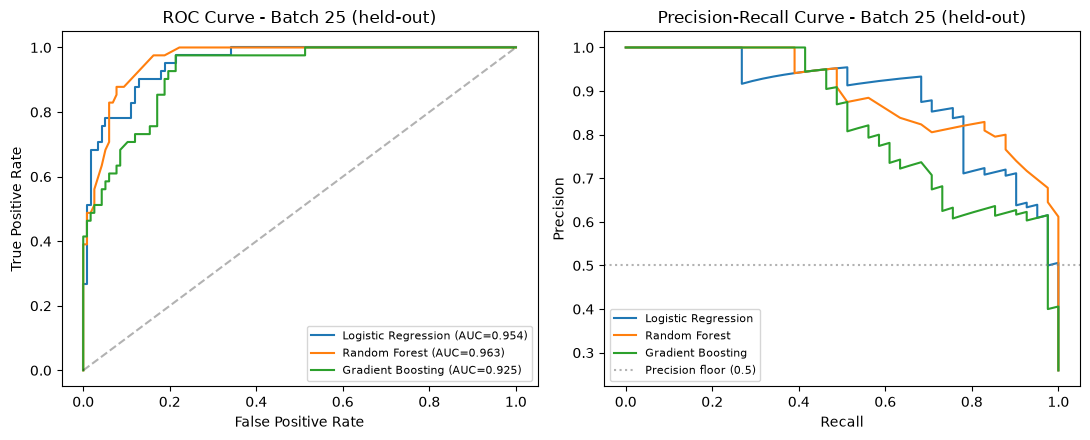

In [36]:
from sklearn.metrics import precision_recall_curve, roc_curve

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

curves = [
    ("Logistic Regression", lr_result["proba_val"], lr_result["y_true_val"], lr_result["at_risk_idx"], lr_result["auc"]),
    ("Random Forest", rf_with["proba_val"], rf_with["y_true_val"], rf_with["at_risk_idx"], rf_with["auc"]),
    ("Gradient Boosting", gb_result["proba_val"], gb_result["y_true_val"], gb_result["at_risk_idx"], gb_result["auc"]),
]

for name, proba, y_true, idx, auc in curves:
    y_bin = (y_true == "At-Risk").astype(int)
    fpr, tpr, _ = roc_curve(y_bin, proba[:, idx])
    axes[0].plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")
axes[0].plot([0,1],[0,1],"k--",alpha=0.3)
axes[0].set_xlabel("False Positive Rate"); axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("ROC Curve - Batch 25 (held-out)")
axes[0].legend(fontsize=8)

for name, proba, y_true, idx, auc in curves:
    y_bin = (y_true == "At-Risk").astype(int)
    prec_c, rec_c, _ = precision_recall_curve(y_bin, proba[:, idx])
    axes[1].plot(rec_c, prec_c, label=name)
axes[1].axhline(0.5, color="gray", linestyle=":", alpha=0.6, label="Precision floor (0.5)")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall Curve - Batch 25 (held-out)")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.savefig("roc_pr_curves.png", dpi=150)
plt.show()

## Phase 15 — Leakage-Free Algorithm Selection (corrects Phase 13)

Phase 13 tuned each candidate model correctly on training-batch CV, but then compared all three models' **Batch 25** results and picked the winner there. That used the held-out batch for model selection, not just final evaluation — the same category of leakage corrected earlier for threshold selection, one level up.

This phase moves algorithm selection inside the cross-validation loop: candidates are compared on pooled out-of-fold performance across Batches 22–24 only, the winner is chosen on that evidence, and only that single model is evaluated once on Batch 25.

In [37]:
def evaluate_candidate_oof(feature_list, model_factory, param_grid, seed=42):
    """Tune + score a candidate using ONLY training batches. Batch 25 never touched."""
    sub_a = df[feature_list + ["binary_label", "cohort"]].dropna()
    train_a = sub_a[sub_a["cohort"].isin(TRAIN_COHORTS)].reset_index(drop=True)
    X_train = train_a[feature_list].values
    y_train = train_a["binary_label"].values
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
    folds = list(cv.split(X_train, y_train))
    keys = list(param_grid.keys())
    rows = []
    for combo in itertools.product(*param_grid.values()):
        params = dict(zip(keys, combo))
        oof = np.zeros((len(y_train), 2)); cref = None
        for tri, vai in folds:
            sc = StandardScaler().fit(X_train[tri])
            Xtr, Xva = sc.transform(X_train[tri]), sc.transform(X_train[vai])
            c = pd.Series(y_train[tri]).value_counts()
            k = max(min(3, c.get("At-Risk", 1) - 1), 1)
            Xr, yr = SMOTE(random_state=seed, k_neighbors=k).fit_resample(Xtr, y_train[tri])
            m = model_factory(**params); m.fit(Xr, yr)
            cref = list(m.classes_); oof[vai] = m.predict_proba(Xva)
        ai = cref.index("At-Risk")
        auc = roc_auc_score((y_train == "At-Risk").astype(int), oof[:, ai])
        for th in np.arange(0.15, 0.60, 0.025):
            pr = predict_binary(oof, cref, ai, th)
            rows.append({**params, "threshold": round(th, 3),
                "OOF Recall": recall_score(y_train, pr, pos_label="At-Risk"),
                "OOF Precision": precision_score(y_train, pr, pos_label="At-Risk", zero_division=0),
                "OOF F1": f1_score(y_train, pr, pos_label="At-Risk"), "OOF AUC": auc})
    res = pd.DataFrame(rows)
    valid = res[res["OOF Precision"] >= 0.5]
    if len(valid) == 0: valid = res
    best = valid.loc[valid["OOF Recall"].idxmax()]
    bp = {}
    for k in keys:
        v = best[k]
        if isinstance(v, float) and not pd.isna(v) and v == int(v) and k in ("n_estimators","max_depth"): v = int(v)
        if k == "max_depth" and isinstance(v, float) and pd.isna(v): v = None
        bp[k] = v
    return {"best_params": bp, "threshold": best["threshold"], "oof_recall": best["OOF Recall"],
            "oof_precision": best["OOF Precision"], "oof_f1": best["OOF F1"], "oof_auc": best["OOF AUC"]}

candidates = [("Logistic Regression", lr_factory, lr_grid),
              ("Random Forest", rf_factory, rf_grid),
              ("Gradient Boosting", gb_factory, gb_grid)]
sel_rows, cfgs = [], {}
for name, fac, grid in candidates:
    r = evaluate_candidate_oof(S3_FEATURES_V2, fac, grid)
    cfgs[name] = (fac, r)
    sel_rows.append({"Model": name, "OOF Recall": round(r["oof_recall"],3),
                     "OOF Precision": round(r["oof_precision"],3),
                     "OOF F1": round(r["oof_f1"],3), "OOF AUC": round(r["oof_auc"],3)})
sel_df = pd.DataFrame(sel_rows)
print("Algorithm comparison \u2014 pooled out-of-fold, Batches 22\u201324 only:")
print(sel_df.to_string(index=False))
winner = sel_df.loc[sel_df["OOF Recall"].idxmax(), "Model"]
print(f"\nSELECTED on training-CV evidence alone: {winner}")

Algorithm comparison — pooled out-of-fold, Batches 22–24 only:
              Model  OOF Recall  OOF Precision  OOF F1  OOF AUC
Logistic Regression       0.967          0.500   0.659    0.919
      Random Forest       0.946          0.518   0.669    0.909
  Gradient Boosting       0.946          0.518   0.669    0.922

SELECTED on training-CV evidence alone: Logistic Regression


In [38]:
w_factory, w_cfg = cfgs[winner]
sub_f = df[S3_FEATURES_V2 + ["binary_label","cohort"]].dropna()
tr_f = sub_f[sub_f["cohort"].isin(TRAIN_COHORTS)].reset_index(drop=True)
va_f = sub_f[sub_f["cohort"] == VAL_COHORT].reset_index(drop=True)
Xtr_f, ytr_f = tr_f[S3_FEATURES_V2].values, tr_f["binary_label"].values

sc_f = StandardScaler().fit(Xtr_f)
c_f = pd.Series(ytr_f).value_counts()
k_f = max(min(3, c_f.get("At-Risk",1)-1), 1)
Xr_f, yr_f = SMOTE(random_state=42, k_neighbors=k_f).fit_resample(sc_f.transform(Xtr_f), ytr_f)
final_model = w_factory(**w_cfg["best_params"]); final_model.fit(Xr_f, yr_f)
cls_f = list(final_model.classes_); ai_f = cls_f.index("At-Risk")
proba_f = final_model.predict_proba(sc_f.transform(va_f[S3_FEATURES_V2].values))
preds_f = predict_binary(proba_f, cls_f, ai_f, w_cfg["threshold"])
yt_f = va_f["binary_label"].values

print(f"=== SINGLE final evaluation of {winner} on Batch 25 ===")
print(f"Recall {recall_score(yt_f,preds_f,pos_label='At-Risk'):.3f}  "
      f"Precision {precision_score(yt_f,preds_f,pos_label='At-Risk',zero_division=0):.3f}  "
      f"F1 {f1_score(yt_f,preds_f,pos_label='At-Risk'):.3f}  "
      f"Accuracy {accuracy_score(yt_f,preds_f):.3f}")
print()
print(pd.DataFrame(confusion_matrix(yt_f,preds_f,labels=["At-Risk","Not-At-Risk"]),
      index=["True At-Risk","True Not-At-Risk"], columns=["Pred At-Risk","Pred Not-At-Risk"]))

rng=np.random.default_rng(42); n=len(yt_f); br,bp_=[],[]
for _ in range(3000):
    i2=rng.integers(0,n,n); yt2,yp2=yt_f[i2],preds_f[i2]
    if (yt2=="At-Risk").sum()==0: continue
    br.append(recall_score(yt2,yp2,pos_label="At-Risk"))
    bp_.append(precision_score(yt2,yp2,pos_label="At-Risk",zero_division=0))
print(f"\nRecall 95% CI [{np.percentile(br,2.5):.3f}, {np.percentile(br,97.5):.3f}]")
print(f"Precision 95% CI [{np.percentile(bp_,2.5):.3f}, {np.percentile(bp_,97.5):.3f}]")

=== SINGLE final evaluation of Logistic Regression on Batch 25 ===
Recall 0.854  Precision 0.714  F1 0.778  Accuracy 0.873

                  Pred At-Risk  Pred Not-At-Risk
True At-Risk                35                 6
True Not-At-Risk            14               103

Recall 95% CI [0.735, 0.953]
Precision 95% CI [0.581, 0.837]


Logistic Regression: n = 415, At-Risk = 92, OOF AUC = 0.919
Random Forest: n = 415, At-Risk = 92, OOF AUC = 0.909
Gradient Boosting: n = 415, At-Risk = 92, OOF AUC = 0.922


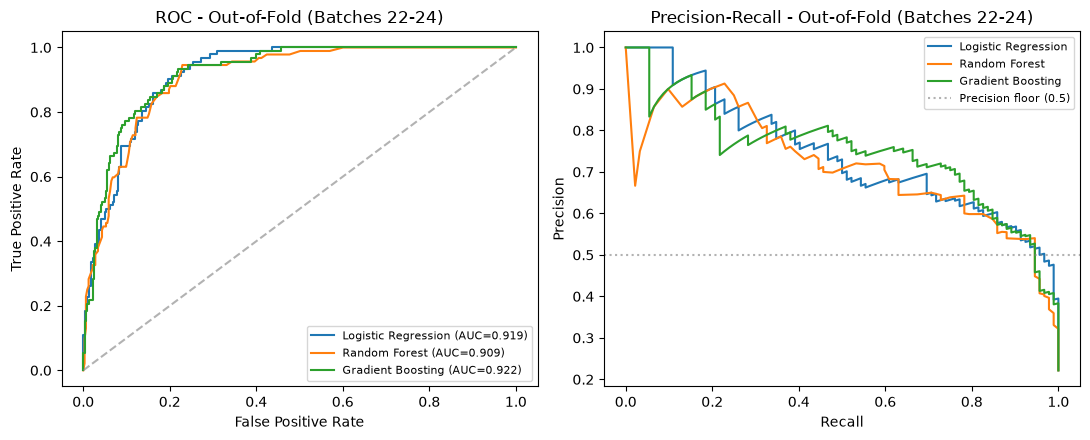

In [39]:
# ---- Figure 2: pooled out-of-fold ROC / PR curves on the development batches ----
from sklearn.metrics import roc_curve, precision_recall_curve

def oof_probabilities(feature_list, model_factory, params, seed=42):
    """Same procedure as evaluate_candidate_oof, but returns the pooled OOF P(At-Risk)."""
    sub_a = df[feature_list + ["binary_label", "cohort"]].dropna()
    train_a = sub_a[sub_a["cohort"].isin(TRAIN_COHORTS)].reset_index(drop=True)
    X = train_a[feature_list].values
    y = train_a["binary_label"].values
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
    oof = np.zeros((len(y), 2)); cref = None
    for tri, vai in cv.split(X, y):
        sc = StandardScaler().fit(X[tri])
        Xtr, Xva = sc.transform(X[tri]), sc.transform(X[vai])
        c = pd.Series(y[tri]).value_counts()
        k = max(min(3, c.get("At-Risk", 1) - 1), 1)
        Xr, yr = SMOTE(random_state=seed, k_neighbors=k).fit_resample(Xtr, y[tri])
        m = model_factory(**params); m.fit(Xr, yr)
        cref = list(m.classes_); oof[vai] = m.predict_proba(Xva)
    return y, oof[:, cref.index("At-Risk")]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for name in ["Logistic Regression", "Random Forest", "Gradient Boosting"]:
    fac, cfg = cfgs[name]
    y_dev, p_dev = oof_probabilities(S3_FEATURES_V2, fac, cfg["best_params"])
    y_bin = (y_dev == "At-Risk").astype(int)
    auc = roc_auc_score(y_bin, p_dev)
    expected = sel_df.loc[sel_df["Model"] == name, "OOF AUC"].iloc[0]
    assert round(auc, 3) == expected, f"{name}: AUC {auc:.3f} does not match Table 4 value {expected}"
    print(f"{name}: n = {len(y_bin)}, At-Risk = {y_bin.sum()}, OOF AUC = {auc:.3f}")
    fpr, tpr, _ = roc_curve(y_bin, p_dev)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")
    prec_c, rec_c, _ = precision_recall_curve(y_bin, p_dev)
    axes[1].plot(rec_c, prec_c, label=name)

axes[0].plot([0, 1], [0, 1], "--", color="gray", alpha=0.6)
axes[0].set_xlabel("False Positive Rate"); axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("ROC - Out-of-Fold (Batches 22-24)"); axes[0].legend(fontsize=8)
axes[1].axhline(0.5, color="gray", linestyle=":", alpha=0.6, label="Precision floor (0.5)")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall - Out-of-Fold (Batches 22-24)"); axes[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig("figure2_oof_roc_pr.png", dpi=300)
plt.show()